### Linear Least Squares For a Polynomial Problem

In [24]:
import numpy as np
import matplotlib.pyplot as plt

In [25]:
u_i = np.random.uniform(-1, 1, 200)
u = np.sort(u_i)
v_i = u**2 + 0.2*np.random.normal(0,1, 200)


In [26]:
A = np.column_stack((u**2, u, np.ones(200)))
b = v_i.reshape(200)

In [27]:
xls = np.linalg.inv(A.T @ A) @ A.T @ b
l2error = np.linalg.norm(v_i - A @ xls, 2)
l2error


np.float64(2.6014381862036617)

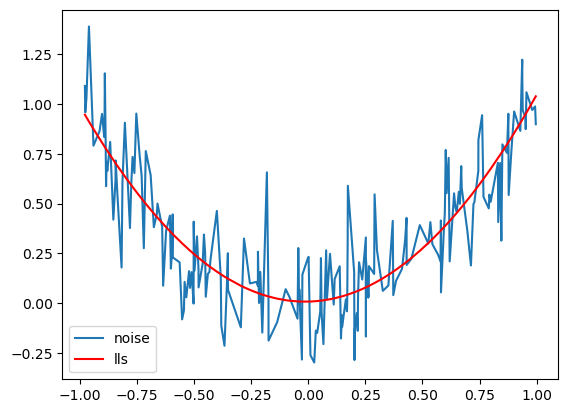

In [28]:
a = xls[0]
b = xls[1]
c = xls[2]
plt.plot(u, v_i,label = 'noise')
plt.plot(u, a*u**2 + b*u + c, color = 'red', label = 'lls')
plt.legend()

### Regularised Least Squares

In [29]:
L = np.zeros((199,200))
for i in range(199):
    L[i,i] = 1
    L[i,i+1] = -1
# Regularisation parameter 

In [30]:
I = np.identity(200)
lda = 100
b = v_i.reshape(200)
xrls = np.linalg.inv(I + lda * L.T @ L) @ b

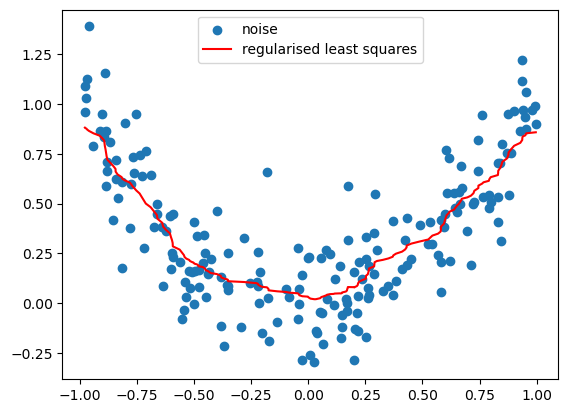

In [31]:
plt.scatter(u, v_i, label = 'noise')
plt.plot(u, xrls, color = 'red', label = 'regularised least squares')
plt.legend()

### Overfitting

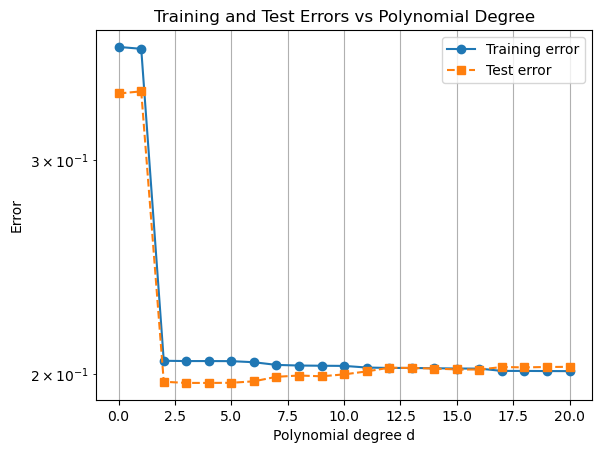

In [32]:
Ns = 200

u = 2 * np.random.rand(Ns) - 1
v = u**2 + 0.2 * np.random.normal(0, 1, Ns)

ut = 2 * np.random.rand(Ns) - 1
vt = ut**2 + 0.2 * np.random.normal(0, 1, Ns)

# Initialise error arrays
etrain = []
etest = []

# Fit polynomial models of degree 0 to 20
for d in range(21):

    # Design matrices: columns are 1, u, u^2, ..., u^d
    A = np.column_stack([u**k for k in range(d + 1)])
    At = np.column_stack([ut**k for k in range(d + 1)])

    # Least squares coefficients
    x = np.linalg.lstsq(A, v, rcond=None)[0]

    # Training and test errors
    etrain.append(np.linalg.norm(A @ x - v) / np.sqrt(Ns))
    etest.append(np.linalg.norm(At @ x - vt) / np.sqrt(Ns))

# Plot errors against polynomial degree
plt.semilogy(range(21), etrain, 'o-', label='Training error')
plt.semilogy(range(21), etest, 's--', label='Test error')

plt.xlabel('Polynomial degree d')
plt.ylabel('Error')
plt.title('Training and Test Errors vs Polynomial Degree')
plt.legend()
plt.grid(True)
plt.show()

In [33]:
v0 = u**2  # noiseless data

err = []
kap = []

for d in range(2, 21):

    # Design matrix with columns 1, u, u^2, ..., u^d
    A = np.column_stack([u**k for k in range(d + 1)])

    # True coefficient vector: coefficient of u^2 is 1
    xtrue = np.zeros(d + 1)
    xtrue[2] = 1

    # Solve using normal equations
    xne = np.linalg.solve(A.T @ A, A.T @ v0)

    # Solve using least squares
    xqr = np.linalg.lstsq(A, v0, rcond=None)[0]

    # Compare coefficient errors
    err.append([
        np.linalg.norm(xne - xtrue),
        np.linalg.norm(xqr - xtrue)
    ])

    # Calculate condition numbers
    kap.append([
        np.linalg.cond(A),
        np.linalg.cond(A.T @ A)
    ])

err = np.array(err)
kap = np.array(kap)

In [34]:
err, kap

(array([[0.00000000e+00, 1.08102371e-15],
        [4.53741172e-18, 1.29213579e-15],
        [5.68885290e-16, 1.25833186e-15],
        [5.73853553e-16, 2.02618192e-15],
        [1.11403646e-14, 3.46858004e-15],
        [1.11907865e-14, 2.76793376e-15],
        [7.53062162e-13, 1.71654303e-14],
        [7.92846998e-13, 4.40099874e-14],
        [2.40961230e-11, 4.43283729e-14],
        [2.68651771e-11, 1.97351293e-13],
        [1.49270697e-10, 5.63350169e-13],
        [1.51274308e-10, 7.84448080e-13],
        [1.49810120e-08, 3.32627086e-12],
        [1.70164949e-08, 5.19713527e-12],
        [8.91624967e-07, 1.31230190e-11],
        [9.95247771e-07, 4.48313045e-11],
        [3.74276757e-05, 4.84031693e-11],
        [3.96542996e-05, 1.69411960e-10],
        [1.27153333e-03, 6.48152727e-10]]),
 array([[3.72444637e+00, 1.38715008e+01],
        [8.12581281e+00, 6.60288338e+01],
        [1.94072851e+01, 3.76642715e+02],
        [4.51123667e+01, 2.03512563e+03],
        [1.05679752e+02, 1.11682

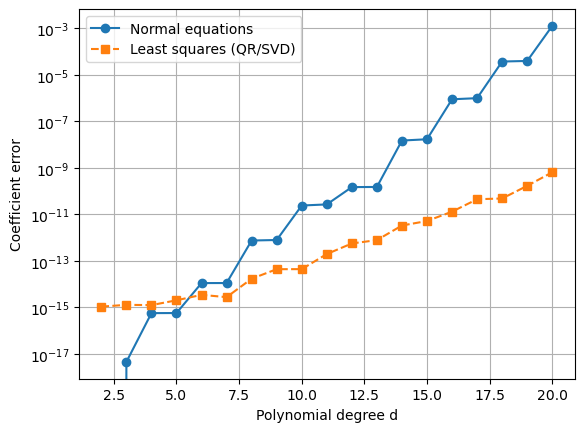

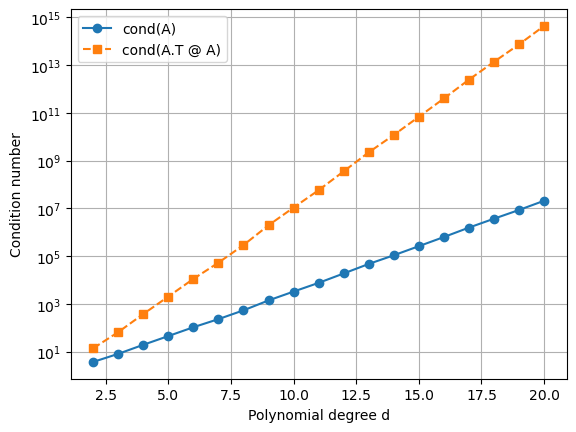

In [35]:
degrees = range(2, 21)

plt.figure()
plt.semilogy(degrees, err[:, 0], 'o-', label='Normal equations')
plt.semilogy(degrees, err[:, 1], 's--', label='Least squares (QR/SVD)')
plt.xlabel('Polynomial degree d')
plt.ylabel('Coefficient error')
plt.legend()
plt.grid(True)
plt.show()

plt.figure()
plt.semilogy(degrees, kap[:, 0], 'o-', label='cond(A)')
plt.semilogy(degrees, kap[:, 1], 's--', label='cond(A.T @ A)')
plt.xlabel('Polynomial degree d')
plt.ylabel('Condition number')
plt.legend()
plt.grid(True)
plt.show()